In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (8,5)

In [22]:

#Load data
df = pd.read_csv("data/health_study_dataset.csv")

#Some easy check on the data.
df.info()
df.duplicated().sum()
#There is no NaN data in any of the columns, Dtypes seems good for the purpose and there is no duplicates in the CSV-file


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


np.int64(0)

In [23]:
#counting mean, median, min, max for the columns age, weight, height, systolic_pb and cholesterol

columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

desc_stats = df[columns].agg(["mean", "median", "min", "max"])

print(desc_stats)


             age   weight     height  systolic_bp  cholesterol
mean    49.42625   73.413  171.84925   149.178625      4.92915
median  50.00000   73.200  171.35000   149.400000      4.97000
min     18.00000   33.700  144.40000   106.800000      2.50000
max     90.00000  114.400  200.40000   185.900000      7.88000


# Graphs

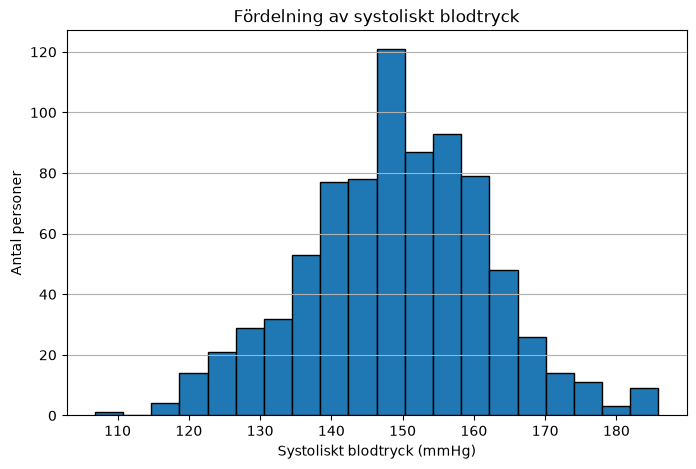

In [24]:
#Histogram for bloodpressure
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"], bins=20, edgecolor="black")
ax.set(title="Fördelning av systoliskt blodtryck", 
       xlabel="Systoliskt blodtryck (mmHg)", 
       ylabel="Antal personer"
       )
ax.grid(True, axis="y")

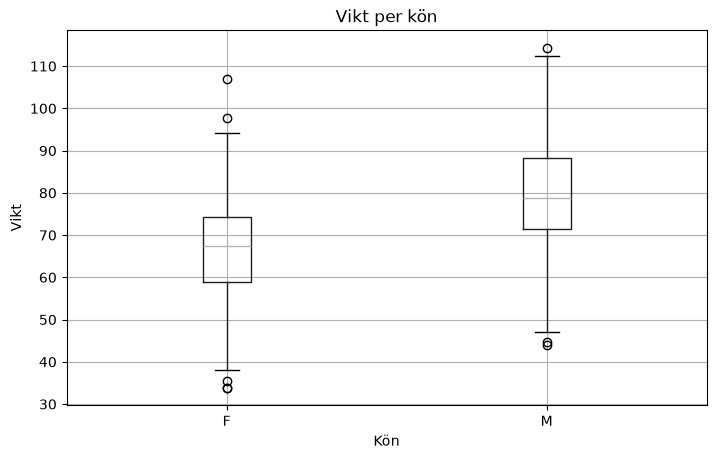

In [25]:
#boxplot for weights categorised by gender
fig, ax = plt.subplots()
df.boxplot(column="weight", by="sex", ax=ax)
ax.set(title="Vikt per kön", 
       xlabel="Kön", 
       ylabel="Vikt"
       )
ax.grid(True)
plt.suptitle("")
plt.show()

Text(0.5, 0.98, '')

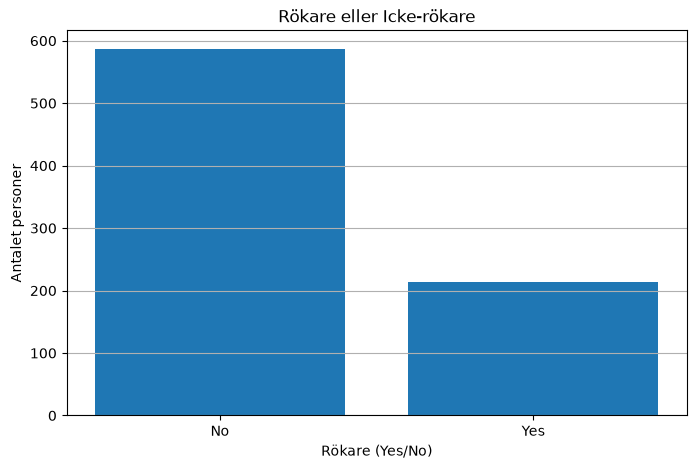

In [26]:
#Bar graph on amount of smokers/non-smokers
smoker_counts = df["smoker"].value_counts()

fig, ax = plt.subplots()
ax.bar(smoker_counts.index, smoker_counts.values)
ax.set(title="Rökare eller Icke-rökare", 
       xlabel="Rökare (Yes/No)", 
       ylabel="Antalet personer"
       )
ax.grid(True, axis="y")
plt.suptitle("")

# Simulation

In [31]:
#Simulation, count share of who has disease

np.random.seed(42)

share_disease = np.mean(df["disease"])


n = 1000
sample = np.random.choice(df["disease"], size=n, replace=True)
share_sample = np.mean(sample)


print(f"Simuleringens andel som har sjukdomen: {share_sample * 100}%. "
      f"Verkliga andelen som har sjukdomen: {share_disease * 100:.2f}%. " 
      f"Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: {(share_sample - share_disease)*100:.2f}%"
    )


Simuleringens andel som har sjukdomen: 6.3%. Verkliga andelen som har sjukdomen: 5.88%. Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: 0.43%


# Confidens interval

## Bootstrap

In [28]:
#CI for mean of systolic_bp bootstrap

mean_systolic_bp = np.mean(df["systolic_bp"])

n_boot = 1000
mean_boot = np.empty(n_boot)

for i in range(n_boot):
    boot_sample = np.random.choice(df["systolic_bp"], size=len(df), replace=True)
    mean_boot[i] = np.mean(boot_sample)

boot_low = np.percentile(mean_boot, 2.5)
boot_high = np.percentile(mean_boot, 97.5)

print(f"Bootstrap metoden ger ett 95%igt konfidensintervall mellan {boot_low:.3f} och {boot_high:.3f} ")

Bootstrap metoden ger ett 95%igt konfidensintervall mellan 148.330 och 150.069 


## Normal approximation


In [29]:
normal_mean_systolic_bp = np.mean(df["systolic_bp"])

n_normal = len(df)
normal_std_systolic_bp = np.std(df["systolic_bp"], ddof=1)
normal_se_systolic_bp = normal_std_systolic_bp / np.sqrt(n_normal)

z = 1.96
half_width = z * normal_se_systolic_bp                              # usually you do std / sqrt(n) but since that is the standarderror, i directly use that variable counting half_width

normal_low = normal_mean_systolic_bp - half_width
normal_high = normal_mean_systolic_bp + half_width

print(f"Normal approximationsmetoden ger ett 95%igt konfidensintervall mellan {normal_low:.3f} och {normal_high:.3f} ")


Normal approximationsmetoden ger ett 95%igt konfidensintervall mellan 148.292 och 150.065 


## Jämförelse resultat mellan konfidensintervallen

De är nästan samma vilket stärker tillit till skattningen. Bootstrap: (148.330 och 150.069 ) Normal approximationen: (148.292 och 150.065)

Vi kan anta att med 95% säkerhet ligger det sanna medelvärdet av blodtrycket i spannet som våra konfidensintervall har plockat fram.

## Hypotesprövning

- Utgångsläge (H0 - Nollhypotesen): Det finns ingen skillnad mellan grupperna.
- Alternativet (H1 - Alternativhypotesen): (Ensidigt) Rökare har högre blodtryck än icke-rökare.


In [30]:
smoker = df.loc[df.smoker == "Yes", "systolic_bp"].to_numpy()
non_smoker = df.loc[df.smoker == "No", "systolic_bp"].to_numpy()

t_value, p_value = stats.ttest_ind(smoker, non_smoker, equal_var=True)

t_stat_w, p_val_w = stats.ttest_ind(smoker, non_smoker, equal_var=False)

print(f"Standard t-test: t={t_value:.3f}, p = {p_value:.4f}")
print(f"Welch    t-test: t= {t_stat_w:.3f}, p = {p_val_w:.4f}")

Standard t-test: t=0.461, p = 0.6450
Welch    t-test: t= 0.450, p = 0.6527


### Resultat och Slutsats (Hypotesprövning)

* **t-värdet:** 0.461
* **p-värdet:** 0.6450

**Tolkning:**

Skulle p-värdet vara 0.05 eller lägre finns det en verklig skillnad mellan rökare och icke-rökare. Utfallet på t-testet blev ungefär 0.645 som är betydligt högre än 0.05 så kan vi därför inte förkasta vår nollhypotes (H0).

Därmed finns det inte tillräckligt med evidens i datan för att hävda att rökare har ett högre blodtryck än icke-rökare.

Det vi ser av vårt t-värde är att rökares medelvärde ser högre ut än icke-rökares medelvärde.

Vi gör även ett Welch test där variansen är olika mot t-testets som gör antagandet om lika varians. Då vi får ett liknande resultat kan det konstateras att resultatet är robust oavsett variansantagande och skapar en trygghet.